<a href="https://colab.research.google.com/github/anish06082007-png/unit-test-/blob/main/Next_Word_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>







### Step 1: Extract and Explore the Dataset
We will extract `/content/archive.zip` to locate the text corpus file(s).

In [1]:
import zipfile
import os

zip_path = '/content/archive.zip'
extract_path = '/content/extracted_data'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

# List the extracted files to find the corpus
for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(os.path.join(root, file))

/content/extracted_data/1661-0.txt


### Step 2: Tokenization, Vocabulary Construction, and Input Sequence Generation
We will tokenize the text corpus into sentences, construct a vocabulary mapping words to indices, and generate input-target sequences (n-gram sequences) for next-word prediction.

In [2]:
import re
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Load the text corpus
corpus_path = '/content/extracted_data/1661-0.txt'
with open(corpus_path, 'r', encoding='utf-8') as f:
    text = f.read().lower()

# Simple sentence splitting on punctuation
sentences = re.split(r'[.\?\!]', text)
sentences = [s.strip() for s in sentences if len(s.strip().split()) > 2]
print(f"Total sentences extracted: {len(sentences)}")

# We will use the first 10,000 sentences for our corpus
subset_sentences = sentences[:10000]

# Initialize and fit tokenizer
tokenizer = Tokenizer(oov_token='<oov>')
tokenizer.fit_on_texts(subset_sentences)
total_words = len(tokenizer.word_index) + 1

print(f"Vocabulary Size: {total_words}")

# Generate input-target sequences
input_sequences = []
for line in subset_sentences:
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        n_gram_sequence = token_list[:i+1]
        input_sequences.append(n_gram_sequence)

# Pad sequences
max_sequence_len = max([len(x) for x in input_sequences])
input_sequences = np.array(pad_sequences(input_sequences, maxlen=max_sequence_len, padding='pre'))

# Create predictors and label
X, y = input_sequences[:,:-1], input_sequences[:,-1]
print(f"Total input-target pairs generated: {len(X)}")
print(f"Max sequence length: {max_sequence_len}")

Total sentences extracted: 6896
Vocabulary Size: 8852
Total input-target pairs generated: 103425
Max sequence length: 105


### Step 3 & 4: Model Selection, Training, and Evaluation
We select a Single LSTM Layer with an Embedding layer. LSTM is ideal for learning temporal and contextual semantics in sequence tasks like text prediction. We compile with `sparse_categorical_crossentropy` to save memory, and track both training accuracy and top-5 accuracy.

In [3]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.metrics import SparseTopKCategoricalAccuracy

# Define the model architecture
model = Sequential([
    Embedding(total_words, 128, input_length=max_sequence_len - 1),
    LSTM(150, return_sequences=False),
    Dense(total_words, activation='softmax')
])

# Compile model with Top-1 (sparse_categorical_accuracy) and Top-5 accuracy metrics
model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy', SparseTopKCategoricalAccuracy(k=5, name='top_5_accuracy')]
)

model.summary()

# Train the model with a moderate batch size to balance speed and stability
history = model.fit(X, y, epochs=15, batch_size=128, validation_split=0.1, verbose=1)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
728/728 ━━━━━━━━━━━━━━━━━━━━ 396s 540ms/step - accuracy: 0.0609 - loss: 6.5902 - top_5_accuracy: 0.1691 - val_accuracy: 0.0723 - val_loss: 6.7722 - val_top_5_accuracy: 0.1915
Epoch 2/15
728/728 ━━━━━━━━━━━━━━━━━━━━ 444s 543ms/step - accuracy: 0.1044 - loss: 5.8715 - top_5_accuracy: 0.2598 - val_accuracy: 0.1071 - val_loss: 6.5087 - val_top_5_accuracy: 0.2535
Epoch 3/15
728/728 ━━━━━━━━━━━━━━━━━━━━ 390s 536ms/step - accuracy: 0.1317 - loss: 5.4947 - top_5_accuracy: 0.2992 - val_accuracy: 0.1234 - val_loss: 6.4839 - val_top_5_accuracy: 0.2693
Epoch 4/15
728/728 ━━━━━━━━━━━━━━━━━━━━ 389s 534ms/step - accuracy: 0.1465 - loss: 5.2443 - top_5_accuracy: 0.3224 - val_accuracy: 0.1295 - val_loss: 6.4872 - val_top_5_accuracy: 0.2755
Epoch 5/15
728/728 ━━━━━━━━━━━━━━━━━━━━ 395s 542ms/step - accuracy: 0.1580 - loss: 5.0410 - top_5_accuracy: 0.3416 - val_accuracy: 0.1327 - val_loss: 6.5245 - val_top_5_accuracy: 0.2822
Epoch 6/15
728/728 ━━━━━━━━━━━━━━━━━━━━ 390s 536ms/step - accuracy: 0.

### Step 5: Evaluate the Model and Visualize Performance
We will evaluate the trained model and inspect training vs validation metrics.

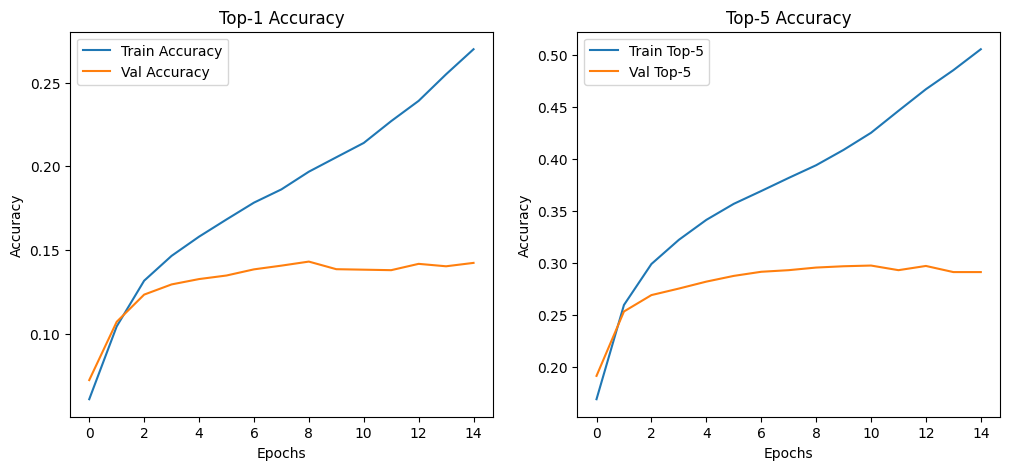

In [4]:
import matplotlib.pyplot as plt

# Plot Training and Validation Accuracy
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Top-1 Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Plot Top-5 Accuracy
plt.subplot(1, 2, 2)
plt.plot(history.history['top_5_accuracy'], label='Train Top-5')
plt.plot(history.history['val_top_5_accuracy'], label='Val Top-5')
plt.title('Top-5 Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

### Step 6: Make Next-Word Predictions on Custom Input Phrases
We will define a prediction function and showcase next-word predictions for 5 different input phrases. We will also analyze the effect of corpus size on performance.

In [5]:
def predict_next_word(seed_text, top_k=5):
    token_list = tokenizer.texts_to_sequences([seed_text])[0]
    token_list = pad_sequences([token_list], maxlen=max_sequence_len - 1, padding='pre')

    preds = model.predict(token_list, verbose=0)[0]
    top_indices = np.argsort(preds)[-top_k:][::-1]

    results = []
    for idx in top_indices:
        for word, index in tokenizer.word_index.items():
            if index == idx:
                results.append((word, preds[idx]))
                break
    return results

# Demonstrate predictions for five input phrases
phrases = [
    "sherlock holmes",
    "the mysterious",
    "i decided to",
    "what did you",
    "he was a"
]

for phrase in phrases:
    predictions = predict_next_word(phrase, top_k=5)
    print(f"\nInput: \"{phrase}\"")
    print("Predicted next words (Top-5):")
    for word, prob in predictions:
        print(f"  - {word}: {prob:.4f}")


Input: "sherlock holmes"
Predicted next words (Top-5):
  - was: 0.1196
  - had: 0.0914
  - sat: 0.0412
  - and: 0.0271
  - with: 0.0226

Input: "the mysterious"
Predicted next words (Top-5):
  - case: 0.0799
  - end: 0.0716
  - nature: 0.0341
  - man: 0.0279
  - court: 0.0268

Input: "i decided to"
Predicted next words (Top-5):
  - be: 0.0556
  - do: 0.0501
  - see: 0.0413
  - have: 0.0384
  - say: 0.0359

Input: "what did you"
Predicted next words (Top-5):
  - gather: 0.0786
  - do: 0.0585
  - know: 0.0480
  - mean: 0.0473
  - have: 0.0441

Input: "he was a"
Predicted next words (Top-5):
  - man: 0.0533
  - very: 0.0401
  - little: 0.0327
  - small: 0.0175
  - member: 0.0173
